In [1]:

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import our dataset containing the lagged variables
df = pd.read_csv(
    "/workspaces/ADA-Sovereign-Spreads/data/processed/sovereign_spreads_lagged.csv",
    parse_dates=["Date"]
)

# Verify the dataset
print("Dataset dimensions:", df.shape)

print("\nLagged variables:")
print([col for col in df.columns if "_lag" in col])

display(df.head())


Dataset dimensions: (3120, 24)

Lagged variables:
['HCPI_rate_lag12m', 'Unemployment_rate_lag12m', 'CISS_Monthly_lag1m', 'VIX_monthly_lag1m', 'GDP_Growth_lag4q', 'Debt_GDP_lag4q', 'Current_Account_lag4q', 'Interest_ex_lag4q', 'Deficit_Surplus_lag4q']


,Date,Quarter,Country,10Y Yields,GDP_Growth,Debt_GDP,Current_Account,Interest_ex,Deficit_Surplus,HCPI_rate,...,VIX_monthly,HCPI_rate_lag12m,Unemployment_rate_lag12m,CISS_Monthly_lag1m,VIX_monthly_lag1m,GDP_Growth_lag4q,Debt_GDP_lag4q,Current_Account_lag4q,Interest_ex_lag4q,Deficit_Surplus_lag4q
0,2000-01-01,2000-Q1,AT,5.793,-0.2,70.8,1.7,4.3,-1.6,-0.4,...,23.202000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2000-02-01,2000-Q1,AT,5.757,-0.2,70.8,1.7,4.3,-1.6,0.8,...,23.595500,NaN,NaN,0.140776,23.202000,NaN,NaN,NaN,NaN,NaN
2,2000-03-01,2000-Q1,AT,5.462,-0.2,70.8,1.7,4.3,-1.6,0.1,...,22.718261,NaN,NaN,0.254105,23.595500,NaN,NaN,NaN,NaN,NaN
3,2000-04-01,2000-Q2,AT,5.562,1.5,71.4,-2.5,3.9,-1.1,-0.2,...,27.164211,NaN,NaN,0.168830,22.718261,NaN,NaN,NaN,NaN,NaN
4,2000-05-01,2000-Q2,AT,5.523,1.5,71.4,-2.5,3.9,-1.1,-0.1,...,26.373182,NaN,NaN,0.214475,27.164211,NaN,NaN,NaN,NaN,NaN


In [2]:
# STEP 1: Inspect the modelling dataset

print("Dataset dimensions:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDate range:")
print(df["Date"].min(), "to", df["Date"].max())

print("\nObservations by country:")
print(df.groupby("Country").size())

print("\nMissing values by variable:")
print(df.isna().sum())

print("\nFirst five observations:")
display(df.head())

Dataset dimensions:
(3120, 24)

Column names:
['Date', 'Quarter', 'Country', '10Y Yields', 'GDP_Growth', 'Debt_GDP', 'Current_Account', 'Interest_ex', 'Deficit_Surplus', 'HCPI_rate', 'Unemployment_rate', '10Y_Spread', 'MonthKey', 'CISS_Monthly', 'VIX_monthly', 'HCPI_rate_lag12m', 'Unemployment_rate_lag12m', 'CISS_Monthly_lag1m', 'VIX_monthly_lag1m', 'GDP_Growth_lag4q', 'Debt_GDP_lag4q', 'Current_Account_lag4q', 'Interest_ex_lag4q', 'Deficit_Surplus_lag4q']

Date range:
2000-01-01 00:00:00 to 2025-12-01 00:00:00

Observations by country:
Country
AT    312
BE    312
DE    312
ES    312
FR    312
GR    312
IE    312
IT    312
NL    312
PT    312
dtype: int64

Missing values by variable:
Date                          0
Quarter                       0
Country                       0
10Y Yields                    0
GDP_Growth                    0
Debt_GDP                      0
Current_Account               0
Interest_ex                   0
Deficit_Surplus               0
HCPI_rate          

,Date,Quarter,Country,10Y Yields,GDP_Growth,Debt_GDP,Current_Account,Interest_ex,Deficit_Surplus,HCPI_rate,...,VIX_monthly,HCPI_rate_lag12m,Unemployment_rate_lag12m,CISS_Monthly_lag1m,VIX_monthly_lag1m,GDP_Growth_lag4q,Debt_GDP_lag4q,Current_Account_lag4q,Interest_ex_lag4q,Deficit_Surplus_lag4q
0,2000-01-01,2000-Q1,AT,5.793,-0.2,70.8,1.7,4.3,-1.6,-0.4,...,23.202000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2000-02-01,2000-Q1,AT,5.757,-0.2,70.8,1.7,4.3,-1.6,0.8,...,23.595500,NaN,NaN,0.140776,23.202000,NaN,NaN,NaN,NaN,NaN
2,2000-03-01,2000-Q1,AT,5.462,-0.2,70.8,1.7,4.3,-1.6,0.1,...,22.718261,NaN,NaN,0.254105,23.595500,NaN,NaN,NaN,NaN,NaN
3,2000-04-01,2000-Q2,AT,5.562,1.5,71.4,-2.5,3.9,-1.1,-0.2,...,27.164211,NaN,NaN,0.168830,22.718261,NaN,NaN,NaN,NaN,NaN
4,2000-05-01,2000-Q2,AT,5.523,1.5,71.4,-2.5,3.9,-1.1,-0.1,...,26.373182,NaN,NaN,0.214475,27.164211,NaN,NaN,NaN,NaN,NaN


In [3]:

# STEP 2: Verify lag alignment for France

france = df[df["Country"] == "FR"].copy()

france = france.sort_values("Date")

columns_to_check = [
    "Date",
    "Quarter",
    "HCPI_rate",
    "HCPI_rate_lag12m",
    "GDP_Growth",
    "GDP_Growth_lag4q"
]

display(
    france.loc[
        france["Date"].between("2021-01-01", "2022-03-01"),
        columns_to_check
    ]
)


,Date,Quarter,HCPI_rate,HCPI_rate_lag12m,GDP_Growth,GDP_Growth_lag4q
1500,2021-01-01,2021-Q1,0.3,-0.5,0.4,-5.0
1501,2021-02-01,2021-Q1,0.0,0.0,0.4,-5.0
1502,2021-03-01,2021-Q1,0.7,0.1,0.4,-5.0
1503,2021-04-01,2021-Q2,0.2,0.0,1.2,-12.2
1504,2021-05-01,2021-Q2,0.3,0.2,1.2,-12.2
1505,2021-06-01,2021-Q2,0.2,0.1,1.2,-12.2
1506,2021-07-01,2021-Q3,0.1,0.4,3.0,15.1
1507,2021-08-01,2021-Q3,0.7,-0.1,3.0,15.1
1508,2021-09-01,2021-Q3,-0.2,-0.6,3.0,15.1
1509,2021-10-01,2021-Q4,0.4,0.0,0.5,0.0


In [4]:

# STEP 3: Create one-month-ahead forecasting targets

df = df.sort_values(["Country", "Date"]).copy()

# Next month's 10-year sovereign yield
df["Yield_next_month"] = (
    df.groupby("Country")["10Y Yields"].shift(-1)
)

# Next month's sovereign spread
df["Spread_next_month"] = (
    df.groupby("Country")["10Y_Spread"].shift(-1)
)

# Display France as an example
display(
    df.loc[
        (df["Country"] == "FR") &
        (df["Date"].between("2022-01-01", "2022-06-01")),
        [
            "Date",
            "10Y Yields",
            "Yield_next_month",
            "10Y_Spread",
            "Spread_next_month"
        ]
    ]
)


,Date,10Y Yields,Yield_next_month,10Y_Spread,Spread_next_month
1512,2022-01-01,0.427,0.616,0.413,0.457
1513,2022-02-01,0.616,0.985,0.457,0.438
1514,2022-03-01,0.985,1.463,0.438,0.528
1515,2022-04-01,1.463,1.645,0.528,0.518
1516,2022-05-01,1.645,1.957,0.518,0.589
1517,2022-06-01,1.957,1.385,0.589,0.560


In [5]:

# STEP 4: Construct the two modelling samples

# Nine lagged economic and financial predictors
macro_predictors = [
    "GDP_Growth_lag4q",
    "Debt_GDP_lag4q",
    "Current_Account_lag4q",
    "Interest_ex_lag4q",
    "Deficit_Surplus_lag4q",
    "HCPI_rate_lag12m",
    "Unemployment_rate_lag12m",
    "CISS_Monthly_lag1m",
    "VIX_monthly_lag1m"
]

# Yield forecasting sample: all 10 countries
yield_predictors = ["10Y Yields"] + macro_predictors

yield_df = df[
    ["Date", "Country", "Yield_next_month"] + yield_predictors
].dropna().copy()

# Spread forecasting sample: exclude Germany
spread_predictors = ["10Y_Spread"] + macro_predictors

spread_df = df.loc[
    df["Country"] != "DE",
    ["Date", "Country", "Spread_next_month"] + spread_predictors
].dropna().copy()

# Display sample sizes
print("Yield sample:", yield_df.shape)
print("Spread sample:", spread_df.shape)

print("\nYield sample period:")
print(yield_df["Date"].min(), "to", yield_df["Date"].max())

print("\nSpread sample period:")
print(spread_df["Date"].min(), "to", spread_df["Date"].max())


Yield sample: (2990, 13)
Spread sample: (2691, 13)

Yield sample period:
2001-01-01 00:00:00 to 2025-11-01 00:00:00

Spread sample period:
2001-01-01 00:00:00 to 2025-11-01 00:00:00


In [6]:

# STEP 5: Chronological train / validation / test split

# Add the month being predicted
for data in [yield_df, spread_df]:
    data["Target_Date"] = (
        data["Date"] + pd.DateOffset(months=1)
    )

def chronological_split(data):
    train = data[data["Target_Date"] < "2019-01-01"].copy()

    validation = data[
        (data["Target_Date"] >= "2019-01-01") &
        (data["Target_Date"] < "2022-01-01")
    ].copy()

    test = data[
        data["Target_Date"] >= "2022-01-01"
    ].copy()

    return train, validation, test

# Yield model
yield_train, yield_val, yield_test = chronological_split(yield_df)

# Spread model
spread_train, spread_val, spread_test = chronological_split(spread_df)

# Display observation counts
for name, train, val, test in [
    ("Yield", yield_train, yield_val, yield_test),
    ("Spread", spread_train, spread_val, spread_test)
]:
    print(f"\n{name} model")
    print("Training:", len(train))
    print("Validation:", len(val))
    print("Test:", len(test))



Yield model
Training: 2150
Validation: 360
Test: 480

Spread model
Training: 1935
Validation: 324
Test: 432


In [7]:

# STEP 6: Evaluate persistence benchmarks

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_persistence(data, target, current_value):
    actual = data[target]
    predicted = data[current_value]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    return mae, rmse

# Evaluate both forecasting tasks
for name, validation, test, target, current in [
    ("Yield", yield_val, yield_test,
     "Yield_next_month", "10Y Yields"),

    ("Spread", spread_val, spread_test,
     "Spread_next_month", "10Y_Spread")
]:
    print(f"\n{name} persistence benchmark")

    for period, data in [
        ("Validation", validation),
        ("Test", test)
    ]:
        mae, rmse = evaluate_persistence(
            data, target, current
        )

        print(
            f"{period}: MAE = {mae:.4f}, "
            f"RMSE = {rmse:.4f}"
        )



Yield persistence benchmark
Validation: MAE = 0.1506, RMSE = 0.1890
Test: MAE = 0.2274, RMSE = 0.3007

Spread persistence benchmark
Validation: MAE = 0.0864, RMSE = 0.1402
Test: MAE = 0.0620, RMSE = 0.0928


In [8]:

# STEP 7A: Train OLS for sovereign yields

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

# Explanatory variables
features = yield_predictors + ["Country"]

# Convert country codes into dummy variables
X_train = pd.get_dummies(
    yield_train[features],
    columns=["Country"],
    drop_first=True,
    dtype=int
)

X_val = pd.get_dummies(
    yield_val[features],
    columns=["Country"],
    drop_first=True,
    dtype=int
)

# Ensure both datasets have identical columns
X_val = X_val.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Dependent variables
y_train = yield_train["Yield_next_month"]
y_val = yield_val["Yield_next_month"]

# Train the model
ols_yield = LinearRegression()
ols_yield.fit(X_train, y_train)

# Predict validation yields
y_pred = ols_yield.predict(X_val)

# Evaluate performance
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print("OLS Yield Model — Validation")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")


OLS Yield Model — Validation
MAE: 0.1720
RMSE: 0.2152


In [9]:

# STEP 7B: Train OLS for sovereign spreads

features_spread = spread_predictors + ["Country"]

# Explanatory variables
X_train_spread = pd.get_dummies(
    spread_train[features_spread],
    columns=["Country"],
    drop_first=True,
    dtype=int
)

X_val_spread = pd.get_dummies(
    spread_val[features_spread],
    columns=["Country"],
    drop_first=True,
    dtype=int
)

X_val_spread = X_val_spread.reindex(
    columns=X_train_spread.columns,
    fill_value=0
)

# Dependent variables
y_train_spread = spread_train["Spread_next_month"]
y_val_spread = spread_val["Spread_next_month"]

# Estimate OLS
ols_spread = LinearRegression()
ols_spread.fit(X_train_spread, y_train_spread)

# Predict validation spreads
spread_pred = ols_spread.predict(X_val_spread)

# Evaluate forecasting performance
mae_spread = mean_absolute_error(
    y_val_spread, spread_pred
)

rmse_spread = np.sqrt(
    mean_squared_error(y_val_spread, spread_pred)
)

print("OLS Spread Model — Validation")
print(f"MAE: {mae_spread:.4f}")
print(f"RMSE: {rmse_spread:.4f}")


OLS Spread Model — Validation
MAE: 0.1328
RMSE: 0.1860


In [10]:

# STEP 8A: Gradient Boosting — Yield model

from sklearn.ensemble import GradientBoostingRegressor

# Initialise the model with standard settings
gb_yield = GradientBoostingRegressor(
    random_state=42
)

# Train on the same data used for OLS
gb_yield.fit(X_train, y_train)

# Predict validation yields
gb_yield_pred = gb_yield.predict(X_val)

# Calculate forecasting errors
gb_yield_mae = mean_absolute_error(
    y_val, gb_yield_pred
)

gb_yield_rmse = np.sqrt(
    mean_squared_error(y_val, gb_yield_pred)
)

print("Gradient Boosting Yield — Validation")
print(f"MAE: {gb_yield_mae:.4f}")
print(f"RMSE: {gb_yield_rmse:.4f}")


Gradient Boosting Yield — Validation
MAE: 0.3345
RMSE: 0.4005


In [11]:

# STEP 8B: Gradient Boosting — Spread model

gb_spread = GradientBoostingRegressor(
    random_state=42
)

# Train the model
gb_spread.fit(X_train_spread, y_train_spread)

# Predict validation spreads
gb_spread_pred = gb_spread.predict(X_val_spread)

# Evaluate
gb_spread_mae = mean_absolute_error(
    y_val_spread, gb_spread_pred
)

gb_spread_rmse = np.sqrt(
    mean_squared_error(y_val_spread, gb_spread_pred)
)

print("Gradient Boosting Spread — Validation")
print(f"MAE: {gb_spread_mae:.4f}")
print(f"RMSE: {gb_spread_rmse:.4f}")


Gradient Boosting Spread — Validation
MAE: 0.2290
RMSE: 0.4917


In [12]:

# STEP 9A: Tune Gradient Boosting for yields

from sklearn.model_selection import ParameterGrid

param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [1, 2, 3],
    "min_samples_leaf": [5, 20]
}

results = []

for params in ParameterGrid(param_grid):

    model = GradientBoostingRegressor(
        **params,
        random_state=42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(
        mean_squared_error(y_val, predictions)
    )

    results.append({
        **params,
        "MAE": mae,
        "RMSE": rmse
    })

# Sort models by validation MAE
results_df = pd.DataFrame(results).sort_values("MAE")

display(results_df.head(10))


,learning_rate,max_depth,min_samples_leaf,n_estimators,MAE,RMSE
49,0.10,3,5,200,0.307117,0.367747
32,0.05,3,5,300,0.309300,0.370741
50,0.10,3,5,300,0.310165,0.373097
44,0.10,2,5,300,0.321009,0.388849
31,0.05,3,5,200,0.323003,0.385664
43,0.10,2,5,200,0.328073,0.389336
26,0.05,2,5,300,0.341856,0.406040
48,0.10,3,5,100,0.342210,0.403928
42,0.10,2,5,100,0.343085,0.407611
25,0.05,2,5,200,0.354937,0.421078


In [13]:

# STEP 9B: Tune Gradient Boosting for spreads

spread_results = []

for params in ParameterGrid(param_grid):

    model = GradientBoostingRegressor(
        **params,
        random_state=42
    )

    model.fit(X_train_spread, y_train_spread)

    predictions = model.predict(X_val_spread)

    mae = mean_absolute_error(
        y_val_spread, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val_spread, predictions
        )
    )

    spread_results.append({
        **params,
        "MAE": mae,
        "RMSE": rmse
    })

# Rank configurations by MAE
spread_results_df = (
    pd.DataFrame(spread_results)
    .sort_values("MAE")
)

display(spread_results_df.head(10))


,learning_rate,max_depth,min_samples_leaf,n_estimators,MAE,RMSE
36,0.10,1,5,100,0.094707,0.148547
19,0.05,1,5,200,0.097273,0.149614
24,0.05,2,5,100,0.100389,0.161866
37,0.10,1,5,200,0.101412,0.156750
8,0.01,2,5,300,0.101486,0.147489
20,0.05,1,5,300,0.102446,0.156109
14,0.01,3,5,300,0.103069,0.147008
38,0.10,1,5,300,0.104104,0.160411
30,0.05,3,5,100,0.104821,0.166746
48,0.10,3,5,100,0.108301,0.172433


In [14]:

# Extract best hyperparameters with correct data types

best_params_spread = {
    "learning_rate": 0.10,
    "max_depth": 1,
    "min_samples_leaf": 5,
    "n_estimators": 100
}

# Train the best spread model
gb_spread_best = GradientBoostingRegressor(
    **best_params_spread,
    random_state=42
)

gb_spread_best.fit(X_train_spread, y_train_spread)

# Predict validation spreads
predictions = gb_spread_best.predict(X_val_spread)

# Calculate errors by country
diagnostics = spread_val[
    ["Date", "Country", "Spread_next_month"]
].copy()

diagnostics["Prediction"] = predictions

diagnostics["Absolute_Error"] = abs(
    diagnostics["Spread_next_month"] -
    diagnostics["Prediction"]
)

country_errors = (
    diagnostics.groupby("Country")["Absolute_Error"]
    .mean()
    .sort_values(ascending=False)
)

display(country_errors)


Country
GR    0.208937
IT    0.178756
PT    0.107902
ES    0.092470
IE    0.076779
BE    0.054443
AT    0.046976
FR    0.043095
NL    0.043006
Name: Absolute_Error, dtype: float64

In [15]:

# STEP 10B: France — Gradient Boosting vs Persistence

france_diagnostics = diagnostics[
    diagnostics["Country"] == "FR"
].copy()

# Persistence assumes next month's spread
# equals the current month's spread
france_persistence = spread_val[
    spread_val["Country"] == "FR"
].copy()

# Calculate errors
gb_mae_france = france_diagnostics[
    "Absolute_Error"
].mean()

persistence_mae_france = mean_absolute_error(
    france_persistence["Spread_next_month"],
    france_persistence["10Y_Spread"]
)

print("France — Spread Forecasting (Validation)")
print(f"Persistence MAE: {persistence_mae_france:.4f}")
print(f"Gradient Boosting MAE: {gb_mae_france:.4f}")

improvement = (
    (persistence_mae_france - gb_mae_france)
    / persistence_mae_france
) * 100

print(f"Improvement over persistence: {improvement:.2f}%")


France — Spread Forecasting (Validation)
Persistence MAE: 0.0323
Gradient Boosting MAE: 0.0431
Improvement over persistence: -33.32%


In [16]:

# STEP 10C: Robustness check — excluding countries

scenarios = {
    "All countries": [],
    "Exclude Greece": ["GR"],
    "Exclude Italy": ["IT"],
    "Exclude Greece & Italy": ["GR", "IT"]
}

results_robustness = []

# Common validation sample for fair comparisons
common_val = spread_val[
    ~spread_val["Country"].isin(["GR", "IT"])
].copy()

for name, excluded in scenarios.items():

    # Change training sample only
    train_subset = spread_train[
        ~spread_train["Country"].isin(excluded)
    ].copy()

    # Create explanatory variables
    X_train_rob = pd.get_dummies(
        train_subset[features_spread],
        columns=["Country"],
        drop_first=True,
        dtype=int
    )

    X_val_rob = pd.get_dummies(
        common_val[features_spread],
        columns=["Country"],
        drop_first=True,
        dtype=int
    )

    X_val_rob = X_val_rob.reindex(
        columns=X_train_rob.columns,
        fill_value=0
    )

    # Train Gradient Boosting
    model = GradientBoostingRegressor(
        **best_params_spread,
        random_state=42
    )

    model.fit(
        X_train_rob,
        train_subset["Spread_next_month"]
    )

    # Predict common validation sample
    predictions = model.predict(X_val_rob)

    # Overall MAE
    overall_mae = mean_absolute_error(
        common_val["Spread_next_month"],
        predictions
    )

    # France-specific MAE
    france_mask = common_val["Country"] == "FR"

    france_mae = mean_absolute_error(
        common_val.loc[
            france_mask, "Spread_next_month"
        ],
        predictions[france_mask.to_numpy()]
    )

    results_robustness.append({
        "Scenario": name,
        "Overall_MAE": overall_mae,
        "France_MAE": france_mae
    })

display(pd.DataFrame(results_robustness))


,Scenario,Overall_MAE,France_MAE
0,All countries,0.066381,0.043095
1,Exclude Greece,0.071076,0.053177
2,Exclude Italy,0.070969,0.048838
3,Exclude Greece & Italy,0.073616,0.053487


In [17]:

# STEP 11A: Combine training and validation data

yield_trainval = pd.concat(
    [yield_train, yield_val]
).sort_values(["Country", "Date"])

spread_trainval = pd.concat(
    [spread_train, spread_val]
).sort_values(["Country", "Date"])

print("Yield training + validation:", len(yield_trainval))
print("Spread training + validation:", len(spread_trainval))

print("\nYield test observations:", len(yield_test))
print("Spread test observations:", len(spread_test))


Yield training + validation: 2510
Spread training + validation: 2259

Yield test observations: 480
Spread test observations: 432


In [18]:

# STEP 11B: Final yield model evaluation

# Prepare predictors
X_trainval_yield = pd.get_dummies(
    yield_trainval[features],
    columns=["Country"],
    drop_first=True,
    dtype=int
)

X_test_yield = pd.get_dummies(
    yield_test[features],
    columns=["Country"],
    drop_first=True,
    dtype=int
)

X_test_yield = X_test_yield.reindex(
    columns=X_trainval_yield.columns,
    fill_value=0
)

# Targets
y_trainval_yield = yield_trainval["Yield_next_month"]
y_test_yield = yield_test["Yield_next_month"]

# 1. Persistence predictions
pred_persistence = yield_test["10Y Yields"]

# 2. OLS predictions
ols_yield_final = LinearRegression()
ols_yield_final.fit(X_trainval_yield, y_trainval_yield)

pred_ols = ols_yield_final.predict(X_test_yield)

# 3. Tuned Gradient Boosting predictions
gb_yield_final = GradientBoostingRegressor(
    learning_rate=0.10,
    max_depth=3,
    min_samples_leaf=5,
    n_estimators=200,
    random_state=42
)

gb_yield_final.fit(X_trainval_yield, y_trainval_yield)

pred_gb = gb_yield_final.predict(X_test_yield)

# Compare test performance
results_yield = []

for name, predictions in [
    ("Persistence", pred_persistence),
    ("OLS", pred_ols),
    ("Gradient Boosting", pred_gb)
]:
    results_yield.append({
        "Model": name,
        "MAE": mean_absolute_error(
            y_test_yield, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_yield, predictions)
        )
    })

display(pd.DataFrame(results_yield))


,Model,MAE,RMSE
0,Persistence,0.227404,0.300686
1,OLS,0.234568,0.301106
2,Gradient Boosting,0.254351,0.329709


In [19]:

# STEP 11C: Final spread model evaluation

# Prepare predictors
X_trainval_spread = pd.get_dummies(
    spread_trainval[features_spread],
    columns=["Country"],
    drop_first=True,
    dtype=int
)

X_test_spread = pd.get_dummies(
    spread_test[features_spread],
    columns=["Country"],
    drop_first=True,
    dtype=int
)

X_test_spread = X_test_spread.reindex(
    columns=X_trainval_spread.columns,
    fill_value=0
)

# Targets
y_trainval_spread = spread_trainval["Spread_next_month"]
y_test_spread = spread_test["Spread_next_month"]

# 1. Persistence predictions
pred_persistence_spread = spread_test["10Y_Spread"]

# 2. OLS predictions
ols_spread_final = LinearRegression()

ols_spread_final.fit(
    X_trainval_spread,
    y_trainval_spread
)

pred_ols_spread = ols_spread_final.predict(
    X_test_spread
)

# 3. Tuned Gradient Boosting predictions
gb_spread_final = GradientBoostingRegressor(
    learning_rate=0.10,
    max_depth=1,
    min_samples_leaf=5,
    n_estimators=100,
    random_state=42
)

gb_spread_final.fit(
    X_trainval_spread,
    y_trainval_spread
)

pred_gb_spread = gb_spread_final.predict(
    X_test_spread
)

# Compare test performance
results_spread = []

for name, predictions in [
    ("Persistence", pred_persistence_spread),
    ("OLS", pred_ols_spread),
    ("Gradient Boosting", pred_gb_spread)
]:
    results_spread.append({
        "Model": name,
        "MAE": mean_absolute_error(
            y_test_spread, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_spread, predictions)
        )
    })

display(pd.DataFrame(results_spread))


,Model,MAE,RMSE
0,Persistence,0.062006,0.092794
1,OLS,0.084746,0.118978
2,Gradient Boosting,0.069076,0.102654


In [20]:

# STEP 12: France-specific test performance

france_results = []

# Yield predictions for France
fr_mask_yield = yield_test["Country"] == "FR"

for name, predictions in [
    ("Persistence", pred_persistence),
    ("OLS", pred_ols),
    ("Gradient Boosting", pred_gb)
]:
    france_results.append({
        "Target": "Yield",
        "Model": name,
        "MAE": mean_absolute_error(
            y_test_yield[fr_mask_yield],
            np.asarray(predictions)[fr_mask_yield.to_numpy()]
        )
    })

# Spread predictions for France
fr_mask_spread = spread_test["Country"] == "FR"

for name, predictions in [
    ("Persistence", pred_persistence_spread),
    ("OLS", pred_ols_spread),
    ("Gradient Boosting", pred_gb_spread)
]:
    france_results.append({
        "Target": "Spread",
        "Model": name,
        "MAE": mean_absolute_error(
            y_test_spread[fr_mask_spread],
            np.asarray(predictions)[fr_mask_spread.to_numpy()]
        )
    })

display(pd.DataFrame(france_results))


,Target,Model,MAE
0,Yield,Persistence,0.223381
1,Yield,OLS,0.250959
2,Yield,Gradient Boosting,0.241181
3,Spread,Persistence,0.049425
4,Spread,OLS,0.054303
5,Spread,Gradient Boosting,0.050216


,Feature,Importance
0,10Y_Spread,0.999042
7,Unemployment_rate_lag12m,0.000358
5,Deficit_Surplus_lag4q,0.000216
3,Current_Account_lag4q,0.000184
8,CISS_Monthly_lag1m,0.000113
4,Interest_ex_lag4q,0.000087
1,GDP_Growth_lag4q,0.000000
2,Debt_GDP_lag4q,0.000000
6,HCPI_rate_lag12m,0.000000
9,VIX_monthly_lag1m,0.000000


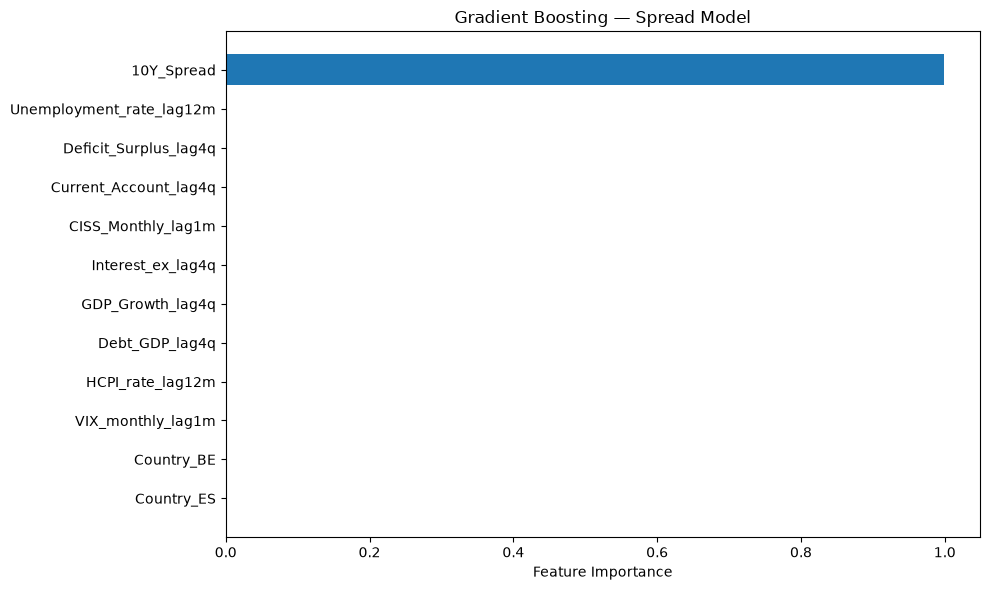

In [21]:

# STEP 13A: Gradient Boosting feature importance

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
importance_df = pd.DataFrame({
    "Feature": X_trainval_spread.columns,
    "Importance": gb_spread_final.feature_importances_
})

# Sort from most to least important
importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

# Display the 12 most important features
display(importance_df.head(12))

# Visualise feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"].head(12)[::-1],
    importance_df["Importance"].head(12)[::-1]
)

plt.xlabel("Feature Importance")
plt.title("Gradient Boosting — Spread Model")
plt.tight_layout()
plt.show()


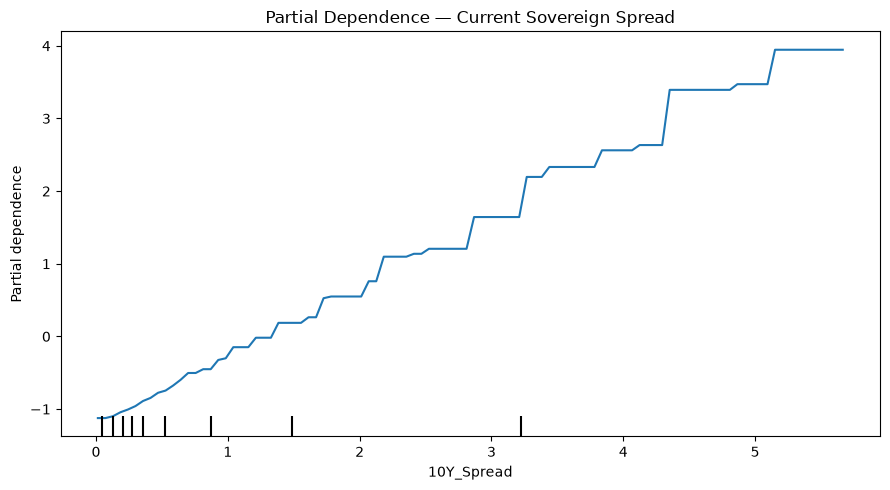

In [22]:

# STEP 13B: Partial dependence of current spreads

from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

PartialDependenceDisplay.from_estimator(
    gb_spread_final,
    X_trainval_spread,
    features=["10Y_Spread"],
    kind="average",
    ax=ax
)

ax.set_title(
    "Partial Dependence — Current Sovereign Spread"
)

ax.set_xlabel("Current 10Y Sovereign Spread")
ax.set_ylabel("Predicted Next-Month Spread")

plt.tight_layout()
plt.show()


In [23]:

# STEP 13C: Extended OLS with nonlinear spread persistence

# Copy the original OLS feature matrices
X_train_extended = X_train_spread.copy()
X_val_extended = X_val_spread.copy()

# Add squared current spread
X_train_extended["Spread_squared"] = (
    X_train_extended["10Y_Spread"] ** 2
)

X_val_extended["Spread_squared"] = (
    X_val_extended["10Y_Spread"] ** 2
)

# Train extended OLS
ols_extended = LinearRegression()

ols_extended.fit(
    X_train_extended,
    y_train_spread
)

# Predict validation spreads
pred_extended = ols_extended.predict(
    X_val_extended
)

# Evaluate
mae_extended = mean_absolute_error(
    y_val_spread,
    pred_extended
)

rmse_extended = np.sqrt(
    mean_squared_error(
        y_val_spread,
        pred_extended
    )
)

print("Extended OLS — Spread Validation")
print(f"MAE: {mae_extended:.4f}")
print(f"RMSE: {rmse_extended:.4f}")


Extended OLS — Spread Validation
MAE: 0.1266
RMSE: 0.1739


In [24]:

# STEP 13D: Gradient Boosting using only current spreads

gb_spread_only = GradientBoostingRegressor(
    **best_params_spread,
    random_state=42
)

# Train using only the current spread
gb_spread_only.fit(
    spread_train[["10Y_Spread"]],
    y_train_spread
)

# Predict validation spreads
pred_spread_only = gb_spread_only.predict(
    spread_val[["10Y_Spread"]]
)

# Evaluate
mae_spread_only = mean_absolute_error(
    y_val_spread,
    pred_spread_only
)

rmse_spread_only = np.sqrt(
    mean_squared_error(
        y_val_spread,
        pred_spread_only
    )
)

print("Gradient Boosting — Current Spread Only")
print(f"MAE: {mae_spread_only:.4f}")
print(f"RMSE: {rmse_spread_only:.4f}")


Gradient Boosting — Current Spread Only
MAE: 0.0911
RMSE: 0.1459


In [25]:

# STEP 14A: Create 12-month-ahead targets

# Sort observations chronologically
df = df.sort_values(["Country", "Date"]).copy()

# Create targets 12 months ahead
df["Yield_12m"] = (
    df.groupby("Country")["10Y Yields"].shift(-12)
)

df["Spread_12m"] = (
    df.groupby("Country")["10Y_Spread"].shift(-12)
)

# Check France as an example
display(
    df.loc[
        (df["Country"] == "FR") &
        (df["Date"].between("2023-01-01", "2023-06-01")),
        [
            "Date",
            "10Y Yields",
            "Yield_12m",
            "10Y_Spread",
            "Spread_12m"
        ]
    ]
)


,Date,10Y Yields,Yield_12m,10Y_Spread,Spread_12m
1524,2023-01-01,2.752,2.6610,0.472,0.5000
1525,2023-02-01,3.119,2.8800,0.476,0.4790
1526,2023-03-01,2.796,2.8030,0.495,0.5100
1527,2023-04-01,2.892,3.0777,0.570,0.4957
1528,2023-05-01,2.848,3.1478,0.576,0.4998
1529,2023-06-01,2.937,3.2880,0.546,0.8030


In [26]:

# STEP 14B: Build 12-month forecasting samples

# Yield sample
yield_12m_df = df[
    ["Date", "Country", "Yield_12m"] + yield_predictors
].dropna().copy()

# Spread sample, excluding Germany
spread_12m_df = df.loc[
    df["Country"] != "DE",
    ["Date", "Country", "Spread_12m"] + spread_predictors
].dropna().copy()

# Define the target dates
for data in [yield_12m_df, spread_12m_df]:
    data["Target_Date"] = (
        data["Date"] + pd.DateOffset(months=12)
    )

# Apply our existing chronological split function
yield_12m_train, yield_12m_val, yield_12m_test = (
    chronological_split(yield_12m_df)
)

spread_12m_train, spread_12m_val, spread_12m_test = (
    chronological_split(spread_12m_df)
)

# Display observation counts
for name, train, val, test in [
    ("Yield 12m", yield_12m_train,
     yield_12m_val, yield_12m_test),

    ("Spread 12m", spread_12m_train,
     spread_12m_val, spread_12m_test)
]:
    print(f"\n{name}")
    print("Training:", len(train))
    print("Validation:", len(val))
    print("Test:", len(test))



Yield 12m
Training: 2040
Validation: 360
Test: 480

Spread 12m
Training: 1836
Validation: 324
Test: 432


In [27]:

# STEP 14C: Correct 12-month training cutoffs

# Validation starts with forecasts made in January 2018.
# Training outcomes must therefore precede January 2018.

yield_12m_train = yield_12m_df[
    yield_12m_df["Target_Date"] < "2018-01-01"
].copy()

spread_12m_train = spread_12m_df[
    spread_12m_df["Target_Date"] < "2018-01-01"
].copy()

print("Corrected yield training:", len(yield_12m_train))
print("Corrected spread training:", len(spread_12m_train))

print("\nFirst validation forecast origin:")
print(yield_12m_val["Date"].min())

print("\nLast training target date:")
print(yield_12m_train["Target_Date"].max())


Corrected yield training: 1920
Corrected spread training: 1728

First validation forecast origin:
2018-01-01 00:00:00

Last training target date:
2017-12-01 00:00:00


In [28]:

# STEP 14D: 12-month persistence benchmarks

def evaluate_12m_persistence(data, target, current):
    actual = data[target]
    predicted = data[current]

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    return mae, rmse


# Evaluate both forecasting tasks
for name, validation, test, target, current in [
    (
        "Yield",
        yield_12m_val,
        yield_12m_test,
        "Yield_12m",
        "10Y Yields"
    ),
    (
        "Spread",
        spread_12m_val,
        spread_12m_test,
        "Spread_12m",
        "10Y_Spread"
    )
]:
    print(f"\n{name} — 12-month persistence")

    for period, data in [
        ("Validation", validation),
        ("Test", test)
    ]:
        mae, rmse = evaluate_12m_persistence(
            data, target, current
        )

        print(
            f"{period}: MAE = {mae:.4f}, "
            f"RMSE = {rmse:.4f}"
        )



Yield — 12-month persistence
Validation: MAE = 0.5590, RMSE = 0.7684
Test: MAE = 0.9379, RMSE = 1.2954

Spread — 12-month persistence
Validation: MAE = 0.2899, RMSE = 0.5057
Test: MAE = 0.2564, RMSE = 0.3725


In [29]:

# STEP 15A: 12-month OLS models — Validation

from sklearn.linear_model import LinearRegression

def evaluate_ols_12m(train, validation, predictors, target):

    features = predictors + ["Country"]

    # Prepare explanatory variables
    X_train = pd.get_dummies(
        train[features],
        columns=["Country"],
        drop_first=True,
        dtype=int
    )

    X_val = pd.get_dummies(
        validation[features],
        columns=["Country"],
        drop_first=True,
        dtype=int
    )

    X_val = X_val.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    # Targets
    y_train = train[target]
    y_val = validation[target]

    # Train OLS
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predict validation outcomes
    predictions = model.predict(X_val)

    # Evaluate
    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))

    return model, mae, rmse


# Yield model
ols_yield_12m, mae_yield_12m, rmse_yield_12m = (
    evaluate_ols_12m(
        yield_12m_train,
        yield_12m_val,
        yield_predictors,
        "Yield_12m"
    )
)

# Spread model
ols_spread_12m, mae_spread_12m, rmse_spread_12m = (
    evaluate_ols_12m(
        spread_12m_train,
        spread_12m_val,
        spread_predictors,
        "Spread_12m"
    )
)

print("12-month OLS — Validation")
print(f"Yield: MAE = {mae_yield_12m:.4f}, RMSE = {rmse_yield_12m:.4f}")
print(f"Spread: MAE = {mae_spread_12m:.4f}, RMSE = {rmse_spread_12m:.4f}")


12-month OLS — Validation
Yield: MAE = 1.0486, RMSE = 1.2478
Spread: MAE = 0.6732, RMSE = 1.0182


In [30]:

# STEP 15B: Tune 12-month Gradient Boosting

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import ParameterGrid

# Hyperparameter grid
param_grid_12m = {
    "learning_rate": [0.03, 0.10],
    "n_estimators": [100, 200],
    "max_depth": [1, 2],
    "min_samples_leaf": [5, 20]
}

def tune_gb_12m(train, validation, predictors, target):

    features = predictors + ["Country"]

    # Create explanatory variables
    X_train = pd.get_dummies(
        train[features],
        columns=["Country"],
        drop_first=True,
        dtype=int
    )

    X_val = pd.get_dummies(
        validation[features],
        columns=["Country"],
        drop_first=True,
        dtype=int
    )

    X_val = X_val.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    y_train = train[target]
    y_val = validation[target]

    results = []

    for params in ParameterGrid(param_grid_12m):

        model = GradientBoostingRegressor(
            **params,
            random_state=42
        )

        model.fit(X_train, y_train)

        predictions = model.predict(X_val)

        results.append({
            **params,
            "MAE": mean_absolute_error(
                y_val, predictions
            ),
            "RMSE": np.sqrt(
                mean_squared_error(y_val, predictions)
            )
        })

    return pd.DataFrame(results).sort_values("MAE")


# Tune yield model
gb_yield_12m_results = tune_gb_12m(
    yield_12m_train,
    yield_12m_val,
    yield_predictors,
    "Yield_12m"
)

# Tune spread model
gb_spread_12m_results = tune_gb_12m(
    spread_12m_train,
    spread_12m_val,
    spread_predictors,
    "Spread_12m"
)

print("Best Gradient Boosting configurations — Yields")
display(gb_yield_12m_results.head(5))

print("\nBest Gradient Boosting configurations — Spreads")
display(gb_spread_12m_results.head(5))


Best Gradient Boosting configurations — Yields


,learning_rate,max_depth,min_samples_leaf,n_estimators,MAE,RMSE
13,0.10,2,5,200,0.850217,0.997491
12,0.10,2,5,100,0.913458,1.060634
15,0.10,2,20,200,0.971039,1.237668
5,0.03,2,5,200,0.996223,1.126660
14,0.10,2,20,100,1.021204,1.267784



Best Gradient Boosting configurations — Spreads


,learning_rate,max_depth,min_samples_leaf,n_estimators,MAE,RMSE
4,0.03,2,5,100,0.436058,0.739042
12,0.10,2,5,100,0.486908,0.784371
5,0.03,2,5,200,0.492822,0.807580
13,0.10,2,5,200,0.508758,0.873569
0,0.03,1,5,100,0.512712,0.759419


In [31]:

# STEP 15C: Prepare leakage-safe 12-month test training

# First test forecast originates in January 2021.
# Training targets must be known before that date.

yield_12m_train_final = yield_12m_df[
    yield_12m_df["Target_Date"] < "2021-01-01"
].copy()

spread_12m_train_final = spread_12m_df[
    spread_12m_df["Target_Date"] < "2021-01-01"
].copy()

# Display sample sizes
print("Final 12-month yield training:",
      len(yield_12m_train_final))

print("Final 12-month spread training:",
      len(spread_12m_train_final))

print("\nLast available training target:")
print(yield_12m_train_final["Target_Date"].max())

print("\nFirst test forecast origin:")
print(yield_12m_test["Date"].min())



Final 12-month yield training: 2280
Final 12-month spread training: 2052

Last available training target:
2020-12-01 00:00:00

First test forecast origin:
2021-01-01 00:00:00


In [32]:

# STEP 15D: Final 12-month yield evaluation

# Prepare predictors
features_yield_12m = yield_predictors + ["Country"]

X_train_12m = pd.get_dummies(
    yield_12m_train_final[features_yield_12m],
    columns=["Country"],
    drop_first=True,
    dtype=int
)

X_test_12m = pd.get_dummies(
    yield_12m_test[features_yield_12m],
    columns=["Country"],
    drop_first=True,
    dtype=int
)

X_test_12m = X_test_12m.reindex(
    columns=X_train_12m.columns,
    fill_value=0
)

# Targets
y_train_12m = yield_12m_train_final["Yield_12m"]
y_test_12m = yield_12m_test["Yield_12m"]

# Persistence benchmark
pred_persistence_12m = yield_12m_test["10Y Yields"]

# OLS
ols_yield_12m_final = LinearRegression()
ols_yield_12m_final.fit(X_train_12m, y_train_12m)

pred_ols_12m = ols_yield_12m_final.predict(X_test_12m)

# Tuned Gradient Boosting
gb_yield_12m_final = GradientBoostingRegressor(
    learning_rate=0.10,
    max_depth=2,
    min_samples_leaf=5,
    n_estimators=200,
    random_state=42
)

gb_yield_12m_final.fit(X_train_12m, y_train_12m)

pred_gb_12m = gb_yield_12m_final.predict(X_test_12m)

# Evaluate
results_yield_12m = []

for name, predictions in [
    ("Persistence", pred_persistence_12m),
    ("OLS", pred_ols_12m),
    ("Gradient Boosting", pred_gb_12m)
]:
    results_yield_12m.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_12m, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_12m, predictions)
        )
    })

display(pd.DataFrame(results_yield_12m))


,Model,MAE,RMSE
0,Persistence,0.937893,1.295445
1,OLS,1.090711,1.404828
2,Gradient Boosting,1.164900,1.474140


In [33]:

# STEP 15E: Final 12-month spread evaluation

features_spread_12m = spread_predictors + ["Country"]

# Prepare explanatory variables
X_train_spread_12m = pd.get_dummies(
    spread_12m_train_final[features_spread_12m],
    columns=["Country"],
    drop_first=True,
    dtype=int
)

X_test_spread_12m = pd.get_dummies(
    spread_12m_test[features_spread_12m],
    columns=["Country"],
    drop_first=True,
    dtype=int
)

X_test_spread_12m = X_test_spread_12m.reindex(
    columns=X_train_spread_12m.columns,
    fill_value=0
)

# Targets
y_train_spread_12m = spread_12m_train_final["Spread_12m"]
y_test_spread_12m = spread_12m_test["Spread_12m"]

# Persistence benchmark
pred_persistence_spread_12m = spread_12m_test["10Y_Spread"]

# OLS
ols_spread_12m_final = LinearRegression()

ols_spread_12m_final.fit(
    X_train_spread_12m,
    y_train_spread_12m
)

pred_ols_spread_12m = ols_spread_12m_final.predict(
    X_test_spread_12m
)

# Tuned Gradient Boosting
gb_spread_12m_final = GradientBoostingRegressor(
    learning_rate=0.03,
    max_depth=2,
    min_samples_leaf=5,
    n_estimators=100,
    random_state=42
)

gb_spread_12m_final.fit(
    X_train_spread_12m,
    y_train_spread_12m
)

pred_gb_spread_12m = gb_spread_12m_final.predict(
    X_test_spread_12m
)

# Evaluate
results_spread_12m = []

for name, predictions in [
    ("Persistence", pred_persistence_spread_12m),
    ("OLS", pred_ols_spread_12m),
    ("Gradient Boosting", pred_gb_spread_12m)
]:
    results_spread_12m.append({
        "Model": name,
        "MAE": mean_absolute_error(
            y_test_spread_12m, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_spread_12m, predictions)
        )
    })

display(pd.DataFrame(results_spread_12m))


,Model,MAE,RMSE
0,Persistence,0.256418,0.372498
1,OLS,0.778890,1.072252
2,Gradient Boosting,0.584571,0.996884


In [34]:

# STEP 16: Expanding-window 12-month spread forecasting

rolling_results = []

features = spread_predictors + ["Country"]

for year in [2021, 2022, 2023, 2024]:

    cutoff = pd.Timestamp(f"{year}-01-01")

    # Training: only outcomes known before the forecast year
    train = spread_12m_df[
        spread_12m_df["Target_Date"] < cutoff
    ].copy()

    # Test: forecast origins during this year
    test = spread_12m_test[
        spread_12m_test["Date"].dt.year == year
    ].copy()

    # Prepare explanatory variables
    X_train = pd.get_dummies(
        train[features],
        columns=["Country"],
        drop_first=True,
        dtype=int
    )

    X_test = pd.get_dummies(
        test[features],
        columns=["Country"],
        drop_first=True,
        dtype=int
    )

    X_test = X_test.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    y_train = train["Spread_12m"]
    y_test = test["Spread_12m"]

    # OLS
    ols = LinearRegression()
    ols.fit(X_train, y_train)
    pred_ols_rolling = ols.predict(X_test)

    # Gradient Boosting: fixed hyperparameters
    gb = GradientBoostingRegressor(
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=5,
        n_estimators=100,
        random_state=42
    )

    gb.fit(X_train, y_train)
    pred_gb_rolling = gb.predict(X_test)

    # Persistence
    pred_persistence_rolling = test["10Y_Spread"]

    for name, predictions in [
        ("Persistence", pred_persistence_rolling),
        ("OLS", pred_ols_rolling),
        ("Gradient Boosting", pred_gb_rolling)
    ]:
        rolling_results.append({
            "Forecast_Year": year,
            "Model": name,
            "MAE": mean_absolute_error(y_test, predictions),
            "RMSE": np.sqrt(
                mean_squared_error(y_test, predictions)
            )
        })

rolling_df = pd.DataFrame(rolling_results)

# Annual forecasting performance
display(rolling_df.pivot(
    index="Forecast_Year",
    columns="Model",
    values="MAE"
))

# Overall performance (equal observations per year)
display(
    rolling_df.groupby("Model")[["MAE", "RMSE"]].mean()
)


Model,Gradient Boosting,OLS,Persistence
Forecast_Year,,,
2021,1.157891,0.910278,0.416030
2022,0.494855,0.764654,0.226392
2023,0.291630,0.607346,0.203363
2024,0.200420,0.423302,0.179887


,MAE,RMSE
Model,,
Gradient Boosting,0.536199,0.786211
OLS,0.676395,0.921683
Persistence,0.256418,0.352913


In [35]:

# STEP 17A: Correct pooled RMSE

pooled_results = []

for model, group in rolling_df.groupby("Model"):

    pooled_mae = group["MAE"].mean()

    # Correct pooled RMSE for equal-sized annual samples
    pooled_rmse = np.sqrt(
        np.mean(group["RMSE"] ** 2)
    )

    pooled_results.append({
        "Model": model,
        "MAE": pooled_mae,
        "RMSE": pooled_rmse
    })

display(pd.DataFrame(pooled_results))


,Model,MAE,RMSE
0,Gradient Boosting,0.536199,0.937847
1,OLS,0.676395,0.942443
2,Persistence,0.256418,0.372498


In [36]:

# STEP 18A: France-specific 12-month forecasting results

france_12m_results = []

# Identify French observations
fr_yield = yield_12m_test["Country"] == "FR"
fr_spread = spread_12m_test["Country"] == "FR"

# Evaluate French yields
for name, predictions in [
    ("Persistence", pred_persistence_12m),
    ("OLS", pred_ols_12m),
    ("Gradient Boosting", pred_gb_12m)
]:
    actual = y_test_12m[fr_yield]
    predicted = np.asarray(predictions)[fr_yield.to_numpy()]

    france_12m_results.append({
        "Target": "Yield",
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    })

# Evaluate French spreads
for name, predictions in [
    ("Persistence", pred_persistence_spread_12m),
    ("OLS", pred_ols_spread_12m),
    ("Gradient Boosting", pred_gb_spread_12m)
]:
    actual = y_test_spread_12m[fr_spread]
    predicted = np.asarray(predictions)[fr_spread.to_numpy()]

    france_12m_results.append({
        "Target": "Spread",
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    })

display(pd.DataFrame(france_12m_results))


,Target,Model,MAE,RMSE
0,Yield,Persistence,0.899742,1.210377
1,Yield,OLS,1.671990,1.824090
2,Yield,Gradient Boosting,1.193466,1.454554
3,Spread,Persistence,0.131040,0.156669
4,Spread,OLS,0.517885,0.666106
5,Spread,Gradient Boosting,0.490214,0.925567


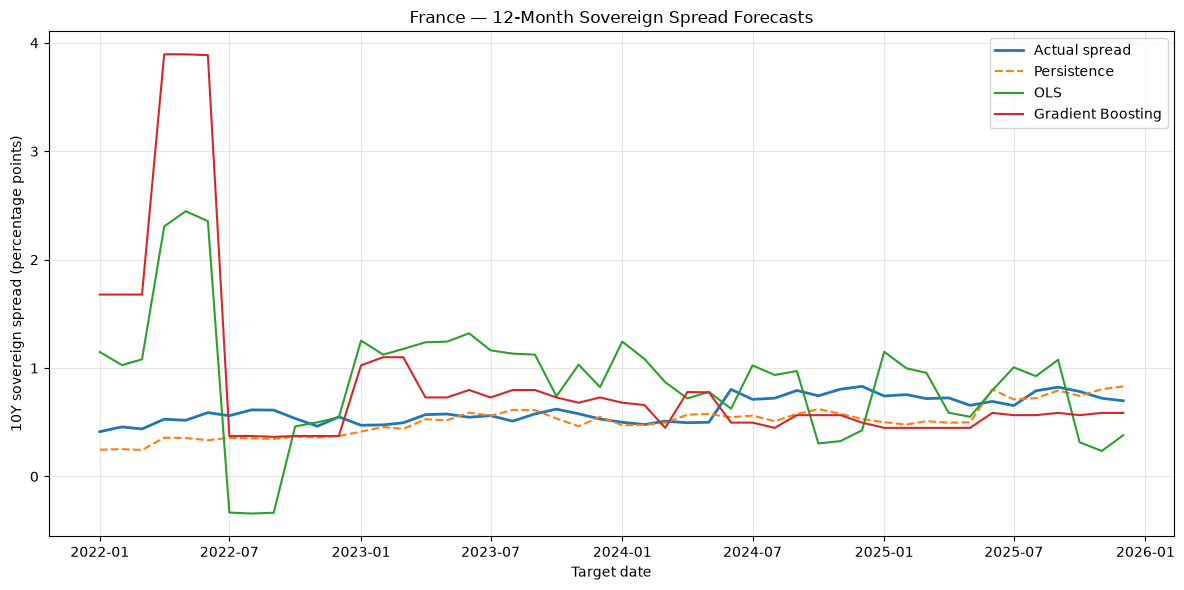

In [37]:

# STEP 18B: Visualise France's 12-month spread forecasts

import matplotlib.pyplot as plt
import numpy as np

# Select France's test observations
france_mask = spread_12m_test["Country"] == "FR"

france_forecasts = spread_12m_test.loc[
    france_mask,
    ["Date", "Target_Date", "Spread_12m", "10Y_Spread"]
].copy()

# Add model forecasts
france_forecasts["OLS"] = np.asarray(
    pred_ols_spread_12m
)[france_mask.to_numpy()]

france_forecasts["Gradient Boosting"] = np.asarray(
    pred_gb_spread_12m
)[france_mask.to_numpy()]

france_forecasts["Persistence"] = (
    france_forecasts["10Y_Spread"]
)

# Sort by target date
france_forecasts = france_forecasts.sort_values(
    "Target_Date"
)

# Plot actual and predicted spreads
plt.figure(figsize=(12, 6))

plt.plot(
    france_forecasts["Target_Date"],
    france_forecasts["Spread_12m"],
    label="Actual spread",
    linewidth=2
)

plt.plot(
    france_forecasts["Target_Date"],
    france_forecasts["Persistence"],
    label="Persistence",
    linestyle="--"
)

plt.plot(
    france_forecasts["Target_Date"],
    france_forecasts["OLS"],
    label="OLS"
)

plt.plot(
    france_forecasts["Target_Date"],
    france_forecasts["Gradient Boosting"],
    label="Gradient Boosting"
)

plt.title("France — 12-Month Sovereign Spread Forecasts")
plt.xlabel("Target date")
plt.ylabel("10Y sovereign spread (percentage points)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [38]:

# STEP 18C: Identify extreme French forecast errors

france_errors = france_forecasts.copy()

# Calculate signed forecast errors
france_errors["GB_Error"] = (
    france_errors["Gradient Boosting"] -
    france_errors["Spread_12m"]
)

france_errors["OLS_Error"] = (
    france_errors["OLS"] -
    france_errors["Spread_12m"]
)

# Absolute errors
france_errors["GB_Absolute_Error"] = (
    france_errors["GB_Error"].abs()
)

# Display largest Gradient Boosting errors
display(
    france_errors.sort_values(
        "GB_Absolute_Error",
        ascending=False
    )[
        [
            "Date",
            "Target_Date",
            "Spread_12m",
            "10Y_Spread",
            "Gradient Boosting",
            "OLS",
            "GB_Error"
        ]
    ].head(10)
)


,Date,Target_Date,Spread_12m,10Y_Spread,Gradient Boosting,OLS,GB_Error
1504,2021-05-01,2022-05-01,0.518,0.3550,3.894638,2.447315,3.376638
1503,2021-04-01,2022-04-01,0.528,0.3570,3.894638,2.306314,3.366638
1505,2021-06-01,2022-06-01,0.589,0.3340,3.886508,2.355513,3.297508
1500,2021-01-01,2022-01-01,0.413,0.2468,1.677910,1.148127,1.264910
1502,2021-03-01,2022-03-01,0.438,0.2444,1.677910,1.080368,1.239910
1501,2021-02-01,2022-02-01,0.457,0.2519,1.677910,1.027093,1.220910
1513,2022-02-01,2023-02-01,0.476,0.4570,1.099970,1.123558,0.623970
1514,2022-03-01,2023-03-01,0.495,0.4380,1.099970,1.176229,0.604970
1512,2022-01-01,2023-01-01,0.472,0.4130,1.024923,1.253329,0.552923
1535,2023-12-01,2024-12-01,0.831,0.5300,0.496575,0.425502,-0.334425


In [39]:

# STEP 19A: Leakage-safe validation for 12-month forecasts

# First forecast origin in the test period
test_origin = yield_12m_test["Date"].min()

# Keep validation targets known before that date
yield_12m_val_safe = yield_12m_val[
    yield_12m_val["Target_Date"] < test_origin
].copy()

spread_12m_val_safe = spread_12m_val[
    spread_12m_val["Target_Date"] < test_origin
].copy()

# Verify the corrected samples
print("First test forecast origin:", test_origin)

print("\nYield validation:")
print("Observations:", len(yield_12m_val_safe))
print("Last target:", yield_12m_val_safe["Target_Date"].max())

print("\nSpread validation:")
print("Observations:", len(spread_12m_val_safe))
print("Last target:", spread_12m_val_safe["Target_Date"].max())

# Confirm training targets precede validation origins
assert (
    yield_12m_train["Target_Date"].max()
    < yield_12m_val_safe["Date"].min()
)

assert (
    spread_12m_train["Target_Date"].max()
    < spread_12m_val_safe["Date"].min()
)


First test forecast origin: 2021-01-01 00:00:00

Yield validation:
Observations: 240
Last target: 2020-12-01 00:00:00

Spread validation:
Observations: 216
Last target: 2020-12-01 00:00:00


In [40]:

# STEP 19B: Retune GB with corrected validation periods

# Yield model
gb_yield_12m_safe = tune_gb_12m(
    yield_12m_train,
    yield_12m_val_safe,
    yield_predictors,
    "Yield_12m"
)

# Spread model
gb_spread_12m_safe = tune_gb_12m(
    spread_12m_train,
    spread_12m_val_safe,
    spread_predictors,
    "Spread_12m"
)

print("Best configurations — 12-month yields")
display(gb_yield_12m_safe.head(5))

print("\nBest configurations — 12-month spreads")
display(gb_spread_12m_safe.head(5))


Best configurations — 12-month yields


,learning_rate,max_depth,min_samples_leaf,n_estimators,MAE,RMSE
13,0.10,2,5,200,0.895307,1.055543
12,0.10,2,5,100,0.935647,1.097384
15,0.10,2,20,200,1.000720,1.267077
5,0.03,2,5,200,1.043979,1.191708
14,0.10,2,20,100,1.046085,1.294109



Best configurations — 12-month spreads


,learning_rate,max_depth,min_samples_leaf,n_estimators,MAE,RMSE
4,0.03,2,5,100,0.439190,0.781737
0,0.03,1,5,100,0.498447,0.729411
2,0.03,1,20,100,0.498447,0.729411
5,0.03,2,5,200,0.503822,0.835066
12,0.10,2,5,100,0.506828,0.819760


In [41]:

# STEP 20A: Does macroeconomic information improve
# 12-month sovereign spread forecasts?

information_sets = {
    "Spread + Country": [
        "10Y_Spread", "Country"
    ],
    "Macro + Country": (
        macro_predictors + ["Country"]
    ),
    "Spread + Macro + Country": (
        ["10Y_Spread"] + macro_predictors + ["Country"]
    )
}

results_information = []

for name, predictors in information_sets.items():

    # Prepare training data
    X_train_info = pd.get_dummies(
        spread_12m_train[predictors],
        columns=["Country"],
        drop_first=True,
        dtype=int
    )

    # Prepare validation data
    X_val_info = pd.get_dummies(
        spread_12m_val_safe[predictors],
        columns=["Country"],
        drop_first=True,
        dtype=int
    )

    X_val_info = X_val_info.reindex(
        columns=X_train_info.columns,
        fill_value=0
    )

    # Train with our selected hyperparameters
    model = GradientBoostingRegressor(
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=5,
        n_estimators=100,
        random_state=42
    )

    model.fit(
        X_train_info,
        spread_12m_train["Spread_12m"]
    )

    predictions = model.predict(X_val_info)

    results_information.append({
        "Information_Set": name,
        "MAE": mean_absolute_error(
            spread_12m_val_safe["Spread_12m"],
            predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                spread_12m_val_safe["Spread_12m"],
                predictions
            )
        )
    })

# Add persistence benchmark
actual = spread_12m_val_safe["Spread_12m"]
persistence = spread_12m_val_safe["10Y_Spread"]

results_information.append({
    "Information_Set": "Persistence",
    "MAE": mean_absolute_error(actual, persistence),
    "RMSE": np.sqrt(mean_squared_error(actual, persistence))
})

display(
    pd.DataFrame(results_information)
    .sort_values("MAE")
)


,Information_Set,MAE,RMSE
3,Persistence,0.316365,0.560676
2,Spread + Macro + Country,0.439190,0.781737
1,Macro + Country,0.717489,1.344170
0,Spread + Country,0.742615,1.560304


In [42]:

# STEP 20B: Compare information sets using OLS

ols_information_results = []

for name, predictors in information_sets.items():

    # Prepare training predictors
    X_train_info = pd.get_dummies(
        spread_12m_train[predictors],
        columns=["Country"],
        drop_first=True,
        dtype=int
    )

    # Prepare validation predictors
    X_val_info = pd.get_dummies(
        spread_12m_val_safe[predictors],
        columns=["Country"],
        drop_first=True,
        dtype=int
    )

    X_val_info = X_val_info.reindex(
        columns=X_train_info.columns,
        fill_value=0
    )

    # Estimate OLS
    model = LinearRegression()

    model.fit(
        X_train_info,
        spread_12m_train["Spread_12m"]
    )

    predictions = model.predict(X_val_info)

    # Evaluate
    ols_information_results.append({
        "Information_Set": name,
        "MAE": mean_absolute_error(
            spread_12m_val_safe["Spread_12m"],
            predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                spread_12m_val_safe["Spread_12m"],
                predictions
            )
        )
    })

# Add persistence
ols_information_results.append({
    "Information_Set": "Persistence",
    "MAE": mean_absolute_error(
        spread_12m_val_safe["Spread_12m"],
        spread_12m_val_safe["10Y_Spread"]
    ),
    "RMSE": np.sqrt(
        mean_squared_error(
            spread_12m_val_safe["Spread_12m"],
            spread_12m_val_safe["10Y_Spread"]
        )
    )
})

display(
    pd.DataFrame(ols_information_results)
    .sort_values("MAE")
)


,Information_Set,MAE,RMSE
3,Persistence,0.316365,0.560676
0,Spread + Country,0.489881,0.853056
2,Spread + Macro + Country,0.621004,0.943084
1,Macro + Country,1.017222,1.595094


In [43]:

# STEP 20C: Check Gradient Boosting overfitting

# Use all predictors
predictors = spread_predictors + ["Country"]

X_train_check = pd.get_dummies(
    spread_12m_train[predictors],
    columns=["Country"],
    drop_first=True,
    dtype=int
)

X_val_check = pd.get_dummies(
    spread_12m_val_safe[predictors],
    columns=["Country"],
    drop_first=True,
    dtype=int
)

X_val_check = X_val_check.reindex(
    columns=X_train_check.columns,
    fill_value=0
)

# Train Gradient Boosting
gb_check = GradientBoostingRegressor(
    learning_rate=0.03,
    max_depth=2,
    min_samples_leaf=5,
    n_estimators=100,
    random_state=42
)

gb_check.fit(
    X_train_check,
    spread_12m_train["Spread_12m"]
)

# Training and validation predictions
pred_train = gb_check.predict(X_train_check)
pred_val = gb_check.predict(X_val_check)

print("Gradient Boosting — 12-month spreads")

print("Training MAE:",
      mean_absolute_error(
          spread_12m_train["Spread_12m"],
          pred_train
      ))

print("Validation MAE:",
      mean_absolute_error(
          spread_12m_val_safe["Spread_12m"],
          pred_val
      ))


Gradient Boosting — 12-month spreads
Training MAE: 0.5877110122005037
Validation MAE: 0.4391904623371836


In [44]:

# STEP 20D: Feature importance — 12-month spread model

importance_12m = pd.DataFrame({
    "Variable": X_train_check.columns,
    "Importance": gb_check.feature_importances_
})

importance_12m = importance_12m.sort_values(
    "Importance",
    ascending=False
)

display(importance_12m.head(15))

# Compare importance across predictor groups
spread_importance = importance_12m.loc[
    importance_12m["Variable"] == "10Y_Spread",
    "Importance"
].sum()

macro_importance = importance_12m.loc[
    importance_12m["Variable"].isin(macro_predictors),
    "Importance"
].sum()

print(f"Current spread importance: {spread_importance:.2%}")
print(f"Macro/stress importance: {macro_importance:.2%}")


,Variable,Importance
0,10Y_Spread,0.626449
3,Current_Account_lag4q,0.128116
7,Unemployment_rate_lag12m,0.106597
5,Deficit_Surplus_lag4q,0.043200
13,Country_GR,0.030807
1,GDP_Growth_lag4q,0.022039
2,Debt_GDP_lag4q,0.021862
8,CISS_Monthly_lag1m,0.010615
4,Interest_ex_lag4q,0.010315
6,HCPI_rate_lag12m,0.000000


Current spread importance: 62.64%
Macro/stress importance: 34.27%


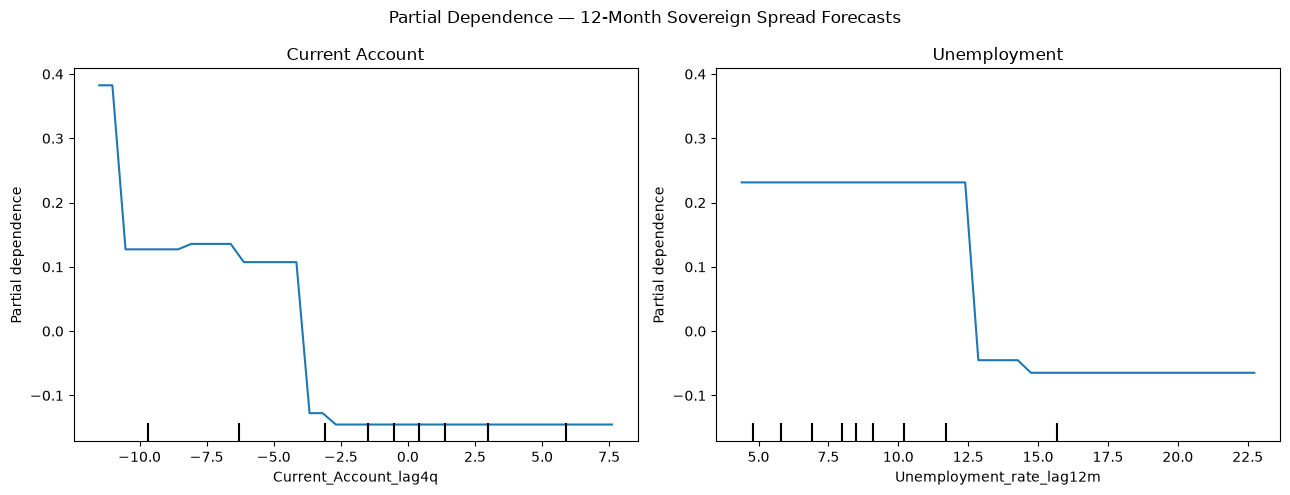

In [45]:

# STEP 21: Partial dependence plots — 12-month spreads

from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

# Variables to investigate
variables = [
    "Current_Account_lag4q",
    "Unemployment_rate_lag12m"
]

# Create the plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

PartialDependenceDisplay.from_estimator(
    gb_check,
    X_train_check,
    features=variables,
    kind="average",
    percentiles=(0.05, 0.95),
    grid_resolution=40,
    ax=axes
)

axes[0].set_title("Current Account")
axes[1].set_title("Unemployment")

fig.suptitle(
    "Partial Dependence — 12-Month Sovereign Spread Forecasts"
)

plt.tight_layout()
plt.show()


In [46]:

# STEP 22: Verify sovereign spread construction

# Retrieve German yields for each month
german_yields = df.loc[
    df["Country"] == "DE",
    ["Date", "10Y Yields"]
].rename(columns={"10Y Yields": "German_Yield"})

# Match German yields with each country
spread_check = df.merge(
    german_yields,
    on="Date",
    how="left"
)

# Reconstruct sovereign spreads
spread_check["Calculated_Spread"] = (
    spread_check["10Y Yields"]
    - spread_check["German_Yield"]
)

# Compare calculated and recorded spreads
spread_check["Difference"] = (
    spread_check["10Y_Spread"]
    - spread_check["Calculated_Spread"]
).abs()

print("Maximum spread discrepancy:")
print(spread_check["Difference"].max())

print("\nAverage discrepancy:")
print(spread_check["Difference"].mean())


Maximum spread discrepancy:
3.552713678800501e-15

Average discrepancy:
1.5227424912168977e-16


In [47]:
import pandas as pd

df = pd.read_csv(
    "../data/processed/sovereign_spreads_lagged.csv",
    parse_dates=["Date"]
)

print(df.shape)
df.head()

(3120, 24)


,Date,Quarter,Country,10Y Yields,GDP_Growth,Debt_GDP,Current_Account,Interest_ex,Deficit_Surplus,HCPI_rate,...,VIX_monthly,HCPI_rate_lag12m,Unemployment_rate_lag12m,CISS_Monthly_lag1m,VIX_monthly_lag1m,GDP_Growth_lag4q,Debt_GDP_lag4q,Current_Account_lag4q,Interest_ex_lag4q,Deficit_Surplus_lag4q
0,2000-01-01,2000-Q1,AT,5.793,-0.2,70.8,1.7,4.3,-1.6,-0.4,...,23.202000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2000-02-01,2000-Q1,AT,5.757,-0.2,70.8,1.7,4.3,-1.6,0.8,...,23.595500,NaN,NaN,0.140776,23.202000,NaN,NaN,NaN,NaN,NaN
2,2000-03-01,2000-Q1,AT,5.462,-0.2,70.8,1.7,4.3,-1.6,0.1,...,22.718261,NaN,NaN,0.254105,23.595500,NaN,NaN,NaN,NaN,NaN
3,2000-04-01,2000-Q2,AT,5.562,1.5,71.4,-2.5,3.9,-1.1,-0.2,...,27.164211,NaN,NaN,0.168830,22.718261,NaN,NaN,NaN,NaN,NaN
4,2000-05-01,2000-Q2,AT,5.523,1.5,71.4,-2.5,3.9,-1.1,-0.1,...,26.373182,NaN,NaN,0.214475,27.164211,NaN,NaN,NaN,NaN,NaN


In [48]:

# Check whether quarterly variables are constant within each quarter

quarterly_vars = [
    "GDP_Growth",
    "Debt_GDP",
    "Current_Account",
    "Interest_ex",
    "Deficit_Surplus"
]

check = df.copy()
check["Calendar_Quarter"] = check["Date"].dt.to_period("Q")

variation = (
    check.groupby(["Country", "Calendar_Quarter"])[quarterly_vars]
    .nunique()
)

print("Quarters with different monthly values:")
print((variation > 1).sum())


Quarters with different monthly values:
GDP_Growth         0
Debt_GDP           0
Current_Account    0
Interest_ex        0
Deficit_Surplus    0
dtype: int64


In [49]:

# Verify the four-quarter lags
df = df.sort_values(["Country", "Date"]).copy()

variables = [
    "GDP_Growth",
    "Debt_GDP",
    "Current_Account",
    "Interest_ex",
    "Deficit_Surplus"
]

for var in variables:
    expected = df.groupby("Country")[var].shift(12)
    actual = df[f"{var}_lag4q"]

    mismatches = (
        (actual - expected).abs() > 1e-10
    ).sum()

    print(f"{var}: {mismatches} mismatches")


GDP_Growth: 0 mismatches
Debt_GDP: 0 mismatches
Current_Account: 0 mismatches
Interest_ex: 0 mismatches
Deficit_Surplus: 0 mismatches


In [50]:

# Check monthly lags

monthly_lags = {
    "HCPI_rate": 12,
    "Unemployment_rate": 12,
    "CISS_Monthly": 1,
    "VIX_monthly": 1
}

for var, months in monthly_lags.items():
    expected = df.groupby("Country")[var].shift(months)
    actual = df[f"{var}_lag{months}m"]

    correct = (
        expected.eq(actual)
        | (expected.isna() & actual.isna())
    )

    print(f"{var}: {(~correct).sum()} mismatches")


HCPI_rate: 0 mismatches
Unemployment_rate: 0 mismatches
CISS_Monthly: 0 mismatches
VIX_monthly: 0 mismatches


In [51]:

# Check forecasting horizons and test periods

audit = df.sort_values(["Country", "Date"]).copy()

for horizon in [1, 12]:
    target_dates = audit.groupby("Country")["Date"].shift(-horizon)
    expected_dates = audit["Date"] + pd.DateOffset(months=horizon)

    valid = target_dates.notna()

    mismatches = (
        target_dates[valid] != expected_dates[valid]
    ).sum()

    test = valid & (target_dates >= "2022-01-01")

    print(f"\n{horizon}-month forecasts:")
    print("Date alignment errors:", mismatches)
    print("Test observations (yields):", test.sum())
    print("Test observations (spreads):",
          (test & audit["Country"].ne("DE")).sum())
    print("First test forecast origin:",
          audit.loc[test, "Date"].min().date())
    print("First test target:",
          target_dates[test].min().date())



1-month forecasts:
Date alignment errors: 0
Test observations (yields): 480
Test observations (spreads): 432
First test forecast origin: 2021-12-01
First test target: 2022-01-01

12-month forecasts:
Date alignment errors: 0
Test observations (yields): 480
Test observations (spreads): 432
First test forecast origin: 2021-01-01
First test target: 2022-01-01
